# Is it quantum, or is it noise?  — START HERE

**A controlled public test of HSBC's claim that a quantum computer improved bond-trading predictions by 34%.**

This notebook is the front door. It explains the whole project in plain English, shows the results on one page, and tells you where everything is. No knowledge of bonds or quantum computing is assumed; unfamiliar words are explained in [GLOSSARY.md](../GLOSSARY.md).

**Contents**

1. The story in one minute
2. Bonds: the five things you need to know
3. The claim, the catch and the three suspects
4. What HSBC actually did
5. What we did
6. What is real and what is simulated
7. The results on one page
8. The real-hardware run
9. How we know the code is right
10. Map of the project

In [1]:
# Set-up: make the project's code importable and keep the output tidy.
import sys, pathlib, warnings
warnings.filterwarnings("ignore")
ROOT = pathlib.Path.cwd().resolve()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
import numpy as np, pandas as pd
pd.set_option("display.width", 170); pd.set_option("display.max_colwidth", 110)
pd.set_option("display.max_rows", 60); pd.set_option("display.float_format", lambda v: f"{v:.4f}")
%matplotlib inline

## 1. The story in one minute

In September 2025 HSBC and IBM announced that a quantum computer had improved a bond-trading prediction by up to 34%, and called it the first evidence of quantum value in trading. Reading the paper closely reveals a catch: the improvement appeared **only on real, noisy hardware**. When the very same quantum circuit was simulated perfectly, there was no improvement. Critics suspected the gain came from noise, from the timing of the hardware runs, or from picking the best of several attempts.

This project rebuilds HSBC's method on public data and adds the controls the critics asked for.

* **Part 1** asks: when a quantum computer seems to help, is it the quantum part, the noise, or the clock?
* **Part 2** (the extension) asks: forget the quantum *features*; can a quantum *kernel* beat classical machine learning?

## 2. Bonds: the five things you need to know

1. **A bond is a tradable loan.** A company borrows money and promises interest plus repayment on a fixed date. The bond can be bought and sold in the meantime.
2. **Price and yield.** A bond's *price* is quoted as a percentage of the amount repaid at the end. Its *yield* is the yearly return you get if you buy today. When the price falls, the yield rises.
3. **Credit spread.** The extra yield a company's bond pays over a government bond. It is the market's price for the risk that the company cannot pay.
4. **Bonds trade through dealers, not on an exchange.** An investor sends a **request for quote (RFQ)** to several banks at once. Each bank replies with a price without seeing the others. The investor picks the best.
5. **Fill.** The winning bank's quote is "filled". Each bank would love to know, before quoting, the probability that its quote will win: **p(fill)**. That number is what HSBC, and this project, try to predict.

## 3. The claim, the catch and the three suspects

| | |
|---|---|
| **The claim** | Feeding trading data through a circuit on IBM's Heron quantum chip, and giving the measurements to ordinary models, improved the prediction score (AUC) by up to 34%. Source: Ciceri et al., arXiv:2509.17715 (a preprint, not peer-reviewed). |
| **The catch** | The same circuit simulated *without* noise gave no improvement. The authors themselves say hardware noise contributed. |
| **Suspect 1: noise** | Perhaps the noise acted like a helpful blur, something ordinary random numbers could do for free. |
| **Suspect 2: selection** | Two circuits with different settings were reported. How many were tried? |
| **Suspect 3: the clock** | A chip's error rates drift over time. If data is sent in date order, the measurements secretly carry the date. |

## 4. What HSBC actually did

The quantum computer did **not** make the predictions. It was a pre-processing step:

```
market data  ->  quantum circuit on 109 qubits  ->  327 measured numbers  ->  ordinary ML model  ->  p(fill)
(216 numbers)     (data sets the gate angles)       (the "quantum features")
```

## 5. What we did

**Part 1: six competing descriptions of the same quote requests, one set of models.**

| Set | What the models are given | What it tells us |
|---|---|---|
| A | the classical inputs | the baseline to beat |
| B | the circuit on a perfect simulated quantum computer | the quantum transformation with zero noise |
| C | the circuit on a noisy simulated chip | does simulated noise help? |
| D | the circuit on real IBM hardware | HSBC's condition (run on 14 Nov 2026 for 400 quote requests) |
| E | B, shrunk and jittered by ordinary random numbers to match the noise | is chip noise just classical noise? |
| F | random classical features, same size | is it just "more non-linear features"? |

Plus a **drift check**: a simulated chip whose errors wander, fed the events once in date order and once in random order.

**Part 2: same inputs, competing learning algorithms.** Four classical models and two classical kernel machines against four quantum kernel machines.

## 6. What is real and what is simulated

| Ingredient | Real or simulated? |
|---|---|
| The bonds, their prices, yields, spreads and trades | **Real** (US corporate bonds, public TRACE data, HSBC's exact dates) |
| The market conditions (rates, VIX, spreads, inflation ...) | **Real** (FRED and others) |
| The 98 inputs | **Real**, computed from the above using only past information |
| The quote requests | **Derived from real trades**: every real customer trade counts as one request |
| The dealer whose quote is filled or not | **Simulated**: a simple rule (Notebook 1, section 6) |
| The quantum computer, perfect version | **Simulated exactly** (checked against Qiskit) |
| The quantum computer, noisy version | **Simulated** with a real chip's published error rates |
| A real quantum computer | **Used** for 400 quote requests (IBM `ibm_fez`, 14 Nov 2026) |

## 7. The results on one page

### Part 1

,mean daily AUC,difference to A,95% low,95% high,relative change (%),real difference?
A classical features,0.5457,0.0000,0.0000,0.0000,0.0000,False
"B quantum, perfect chip",0.5291,-0.0165,-0.0232,-0.0097,-3.0328,True
"C quantum, noisy chip",0.5281,-0.0176,-0.0234,-0.0115,-3.2174,True
E B + classical noise,0.5251,-0.0206,-0.0273,-0.0139,-3.7721,True
F random classical features,0.5379,-0.0077,-0.0134,-0.0024,-1.4142,True


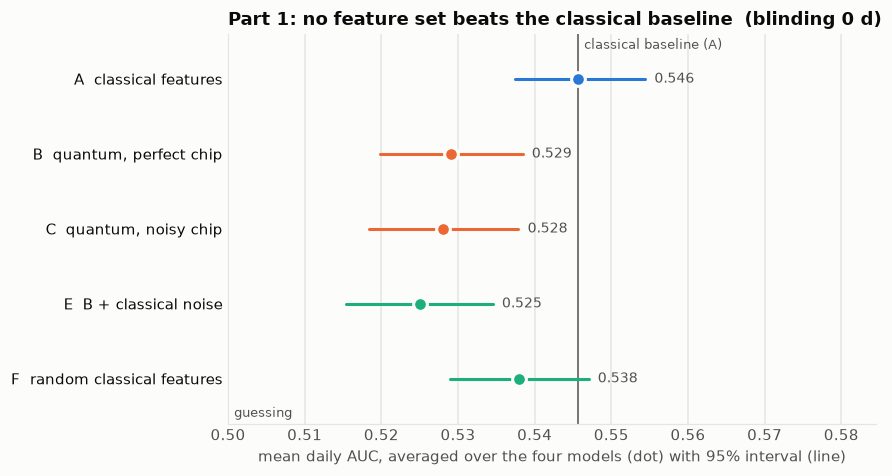

In [2]:
from qon.analysis import load, part1_table, fig_part1_headline, paired_difference, part2_table, fig_part2, METHOD_LABEL
pred = load("part1_predictions")
fig_part1_headline(pred, blinding=0);
t = part1_table(pred, 0, "All")[["mean_auc", "diff_vs_A", "diff_ci_low", "diff_ci_high", "relative_gain_%", "significant"]]
t.index = ["A  classical features", "B  quantum, perfect chip", "C  quantum, noisy chip", "E  B + classical noise", "F  random classical features"]
t.columns = ["mean daily AUC", "difference to A", "95% low", "95% high", "relative change (%)", "real difference?"]
t.round(4)

In [3]:
d = paired_difference(pred, "C_drift_chrono", "C_drift_random", 0)
print("Drift check: AUC with events sent in date order minus AUC with events sent in random order")
print(f"   {d['mean_diff']:+.4f}   (95% interval {d['ci_low']:+.4f} to {d['ci_high']:+.4f})")

Drift check: AUC with events sent in date order minus AUC with events sent in random order
   +0.0000   (95% interval -0.0046 to +0.0043)


**Part 1 in plain English** (AUC: 0.5 is guessing, 1.0 is perfect)

* **Is it quantum? No.** On a perfect quantum computer the quantum features score *lower* than the classical inputs (about 3% lower in HSBC's units, where HSBC report 34% higher for hardware). HSBC's own noiseless simulation also showed no gain.
* **Is it noise? No.** A noisy simulated chip scores the same as a perfect one, and the same as a classical imitation of its noise.
* **Is it the clock?** The clock is real: sent in date order, a drifting chip's output reveals the date almost perfectly (Notebook 2). But it did not improve predictions here, because our classical inputs already contain the date in disguise.
* **Is it just more features? No.** Random classical features do not help either.

So everything we can simulate agrees with HSBC's simulations, and none of it shows a quantum benefit. The claim rests entirely on real hardware.

* **And on real hardware? No gain either.** On 14 November 2026 the circuit ran on a real IBM chip for 400 quote requests. Its features scored 0.50, guessing level, and no different from the classical inputs on the same requests. The chip's noise does reveal *when in the run* a circuit was executed, so the clock is real on hardware too; our random run order kept it from leaking dates. The test is small and could only have caught a large effect (section 8 and Notebook 5).

### Part 2

,family,mean daily AUC,difference to best classical,95% low,95% high,real difference?
Random forest,classical,0.5441,0.0000,0.0000,0.0000,False
Gradient boosting,classical,0.5388,-0.0054,-0.0235,0.0140,False
Logistic regression,classical,0.5373,-0.0068,-0.0299,0.0160,False
Neural network,classical,0.5298,-0.0143,-0.0377,0.0068,False
"SVM, fidelity quantum kernel (4096 shots)",quantum,0.5094,-0.0347,-0.0643,-0.0070,True
"SVM, fidelity quantum kernel",quantum,0.4962,-0.0479,-0.0760,-0.0211,True
"SVM, linear kernel",classical,0.4918,-0.0523,-0.0849,-0.0217,True
"SVM, projected quantum kernel",quantum,0.4909,-0.0532,-0.0885,-0.0204,True
"SVM, projected quantum kernel (noisy chip)",quantum,0.4897,-0.0544,-0.0883,-0.0221,True
"SVM, classical RBF kernel",classical,0.4875,-0.0567,-0.0857,-0.0274,True


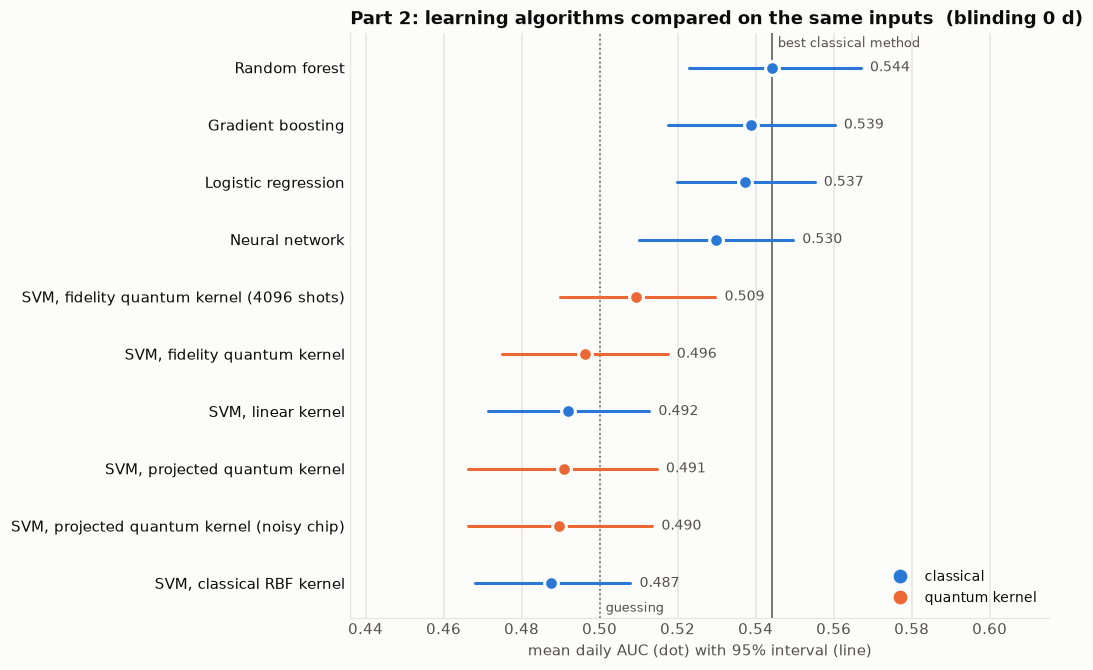

In [4]:
pred2 = load("part2_predictions")
fig_part2(pred2, blinding=0);
t2 = part2_table(pred2, 0)
base = t2.attrs["baseline"]
out = t2[["family", "mean_auc", f"diff_vs_{base}", "diff_ci_low", "diff_ci_high", "significant"]].copy()
out.index = [METHOD_LABEL[m] for m in out.index]
out.columns = ["family", "mean daily AUC", "difference to best classical", "95% low", "95% high", "real difference?"]
out.round(4)

In [5]:
# FOLLOW-UP (added after the planned result was seen): the same kernels with kernel ridge regression.
follow = pd.concat([pred2[~pred2["model"].str.startswith("SVM")], load("part2_followup_predictions")])
t3 = part2_table(follow, 0)
base = t3.attrs["baseline"]
out = t3[["family", "mean_auc", f"diff_vs_{base}", "diff_ci_low", "diff_ci_high", "significant"]].copy()
out.index = [METHOD_LABEL[m] for m in out.index]
out.columns = ["family", "mean daily AUC", "difference to best classical", "95% low", "95% high", "real difference?"]
out.index.name = "FOLLOW-UP"
out.round(4)

,family,mean daily AUC,difference to best classical,95% low,95% high,real difference?
FOLLOW-UP,,,,,,
"Kernel ridge, linear kernel",classical,0.5455,0.0000,0.0000,0.0000,False
Random forest,classical,0.5441,-0.0014,-0.0247,0.0221,False
"Kernel ridge, classical RBF kernel",classical,0.5410,-0.0045,-0.0213,0.0126,False
Gradient boosting,classical,0.5388,-0.0068,-0.0315,0.0170,False
Logistic regression,classical,0.5373,-0.0082,-0.0198,0.0038,False
"Kernel ridge, fidelity quantum kernel",quantum,0.5371,-0.0084,-0.0203,0.0031,False
"Kernel ridge, fidelity quantum kernel (4096 shots)",quantum,0.5338,-0.0117,-0.0245,0.0002,False
"Kernel ridge, projected quantum kernel (noisy chip)",quantum,0.5306,-0.0149,-0.0374,0.0094,False
"Kernel ridge, projected quantum kernel",quantum,0.5301,-0.0154,-0.0376,0.0082,False


**Part 2 in plain English**

* **Planned test (the chart and the first table):** kernel machines were built with a standard method called an SVM. Every one of them, quantum *and* classical, scored at guessing level, while ordinary models scored about 0.54. That means the SVM itself fails on such a weak signal, so this test cannot tell a good kernel from a bad one.
* **Follow-up (the second table):** we therefore repeated the comparison with a kernel method that suits weak signals (kernel ridge regression). This was added after seeing the first result and is labelled as such. Now the kernels work, and the quantum kernels score about the same as, or slightly below, the classical ones.
* **Either way: no quantum kernel beats classical machine learning here.** The best performer is a plain linear method.

## 8. The real-hardware run

**Set D has been run.** It is the one experiment that tests HSBC's actual claim. On 14 November 2026 the circuit ran on IBM's `ibm_fez` for 400 quote requests, in random order, with the controls fixed beforehand (sentinel circuits, a frozen plan). It used 6.6 of the free plan's 10 minutes of quantum time.

| What the models were given (same 400 requests) | AUC | 95% range |
|---|---|---|
| A: classical inputs | 0.45 | 0.39 to 0.52 |
| B: circuit, perfect simulation | 0.49 | 0.40 to 0.58 |
| C: circuit, noisy simulation | 0.52 | 0.44 to 0.60 |
| **D: circuit on the real IBM chip** | **0.50** | **0.41 to 0.59** |
| E: classical imitation of the chip's noise | 0.48 | 0.41 to 0.57 |
| F: random classical features | 0.52 | 0.44 to 0.61 |

* **No hardware advantage.** D minus A is +0.05, with a range of −0.04 to +0.13. HSBC report hardware scores of 0.75 to 0.97.
* **The clock exists on real hardware.** The chip's noise reveals whether a circuit ran early or late in the run (AUC 0.77). The random order kept that from leaking dates.
* **A small test.** Every input is at guessing level with only 400 requests, so only a very large effect could have shown. It does not prove HSBC wrong.

[Notebook 5](05_hardware_run_and_limitations.ipynb) has the full account. What is still to do: a date-ordered batch on hardware, a second chip or day, and many more requests.

## 9. How we know the code is right

The project has an automated test-suite (`tests/`). It checks, among other things, that

* the simulator gives the same numbers as three independent Qiskit simulators, including the one HSBC used, on the full 109 qubits;
* **no input can see the future**: destroying all data from the test day onwards changes nothing;
* a sample of inputs matches a slow, independent recomputation straight from the raw file;
* every "filled" label can be re-derived from raw prices;
* training data is always strictly older than the test day;
* the backtest finds a signal that was planted on purpose, and finds nothing in pure noise;
* the hardware pipeline assigns each measurement to the right qubit;
* the hardware run cannot spend more quantum time than its budget, and loses nothing if it is interrupted.

The cell below runs all of them now.

In [6]:
import subprocess, sys as _sys
res = subprocess.run([_sys.executable, "-m", "pytest", "-q", "--color=no", "-p", "no:cacheprovider", str(ROOT / "tests")],
                     capture_output=True, text=True, cwd=ROOT)
print(res.stdout.strip().splitlines()[-1])

55 passed in 75.61s (0:01:15)


## 10. Map of the project

**Notebooks (read in this order)**

| Notebook | What it explains |
|---|---|
| **0 — Start here** | this page |
| [1 — The data](01_data_and_fill_label.ipynb) | where the data comes from, the 98 inputs, what "filled" means |
| [2 — The circuit](02_quantum_circuit_and_feature_sets.ipynb) | qubits and gates, the 109-qubit circuit, how it is simulated, noise, the feature sets, drift |
| [3 — Part 1 results](03_part1_results.ipynb) | is it quantum, noise or the clock? |
| [4 — Part 2 results](04_part2_quantum_kernels.ipynb) | the extension: quantum kernels |
| [5 — Hardware run and limitations](05_hardware_run_and_limitations.ipynb) | the real-hardware result, how it was run, every limitation, next steps |

**Other documents**

| File | What it is |
|---|---|
| [README.md](../README.md) | overview and how to run everything |
| [GLOSSARY.md](../GLOSSARY.md) | every term in plain English |
| [PREREGISTRATION.md](../PREREGISTRATION.md) | the plan, frozen before the hardware run, and the record of the run |
| [docs/FEATURE_COVERAGE.md](../docs/FEATURE_COVERAGE.md) | what happened to each of the 216 features |

**Code** (each file starts with a plain-English explanation)

| Folder | Contents |
|---|---|
| `src/qon/` | the project's code: data, features, fill label, circuit, simulators, noise, backtest, kernels, hardware, analysis |
| `scripts/` | the steps, numbered in the order to run them (01 to 07) |
| `tests/` | the checks described above |
| `results/` | saved predictions, tables and figures |
| `data/` | downloaded and processed data (not shared, re-created by the scripts) |